# Whisper: Hands-on Implementation (Arabic & English)

This is the practical side of [whisper_master_guide.md](whisper_master_guide.md). The paper is Radford et al., *Robust Speech Recognition via Large-Scale Weak Supervision* (OpenAI, 2022), [arXiv:2212.04356](https://arxiv.org/abs/2212.04356).

| # | Section | What I do there |
|---|---|---|
| 1 | Setup & audio | Load a short English sample and my Egyptian Arabic clip with its ground truth |
| 2 | Log-Mel | See how any audio becomes an 80 x 3000 input |
| 3 | Inside the model | Trace the shapes from the encoder to the decoder |
| 4 | Special tokens | Language detection, transcribe vs translate |
| 5 | Long-form decoding | Timestamps and the compression-ratio check |
| 6 | Evaluate | WER / CER, then compare tiny, base, small, turbo and the .en models |
| 7 | CPU vs GPU, offline vs online | faster-whisper on both devices, a fully offline run, and free online APIs |

I ran this on Google Colab with a T4 GPU (Runtime > Change runtime type). Torch and ffmpeg are already there. The audio and the ground truth are pulled from this repo, and if that fails Colab asks you to upload them. Model sizes: tiny 75 MB, base 140 MB, small 460 MB, turbo 1.6 GB.

## 1. Setup & audio

In [1]:
!pip install -q openai-whisper faster-whisper jiwer datasets soundfile librosa

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 18.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 65.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 MB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 82.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 109.0 MB/s eta 0:00:00


In [2]:
import os, re, time, zlib, numpy as np, torch, whisper, matplotlib.pyplot as plt
from datasets import load_dataset
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FP16 = DEVICE == "cuda"
model = whisper.load_model("base", device=DEVICE)
print(DEVICE, f"{sum(p.numel() for p in model.parameters())/1e6:.0f}M params", model.dims)

100%|████████████████████████████████████████| 139M/139M [00:01<00:00, 142MiB/s]


cuda 72M params ModelDimensions(n_mels=80, n_audio_ctx=1500, n_audio_state=512, n_audio_head=8, n_audio_layer=6, n_vocab=51865, n_text_ctx=448, n_text_state=512, n_text_head=8, n_text_layer=6)


In [4]:
# English: a tiny LibriSpeech sample (a few MB)
ds = load_dataset("hf-internal-testing/librispeech_asr_dummy", "clean", split="validation")
en_audio = ds[0]["audio"]["array"].astype(np.float32); en_ref = ds[0]["text"]

# Arabic: audio.wav + ground_truth.txt from this folder of the repo
import urllib.request
from pathlib import Path
REPO_RAW = ("https://raw.githubusercontent.com/Ziadashraf301/AI-Data-Science-Lab/master/"
            "audio-processing/03-foundation-ssl-transformers/whisper-deep-dive/")
DATA = ["audio.wav", "ground_truth.txt"]

def fetch(name):
    if Path(name).exists(): return True
    try:
        urllib.request.urlretrieve(REPO_RAW + name, name); return True
    except Exception as e:
        print(f"GitHub fetch failed for {name}: {e}"); return False

missing = [f for f in DATA if not fetch(f)]
if missing:  # fallback: upload from your PC (Colab only)
    from google.colab import files
    print("Please upload:", missing); files.upload()

AR_PATH = "audio.wav"
AR_REF = " ".join(Path("ground_truth.txt").read_text(encoding="utf-8").split())
ar_audio = whisper.load_audio(AR_PATH)  # 16 kHz mono float32 (uses ffmpeg)
print(f"EN {len(en_audio)/16000:.1f}s | AR {len(ar_audio)/16000:.1f}s")
print("AR reference:", AR_REF[:120], "...")

GitHub fetch failed for ground_truth.txt: HTTP Error 404: Not Found
Please upload: ['ground_truth.txt']


Saving audio.wav to audio (1).wav
Saving ground_truth.txt to ground_truth.txt
EN 5.9s | AR 69.5s
AR reference: الحجز في العيادات مش مجرد شات. الحجز محتاج تنظيم وتركيز في التفاصيل. في المجال الطبي الثقة والرد السريع مهمين جدا. واغلب ...


Note: in this run `ground_truth.txt` gave a 404 because I hadn't pushed it yet, so I uploaded it by hand. Once both files are on GitHub the cell just downloads them.

## 2. Log-Mel, step by step
Whisper always works on exactly 30 seconds: 480,000 samples, which gives 3,000 frames (hop of 160) with 80 Mel bins each.

raw: (93680,) -> padded: (480000,) -> mel: (80, 3000)


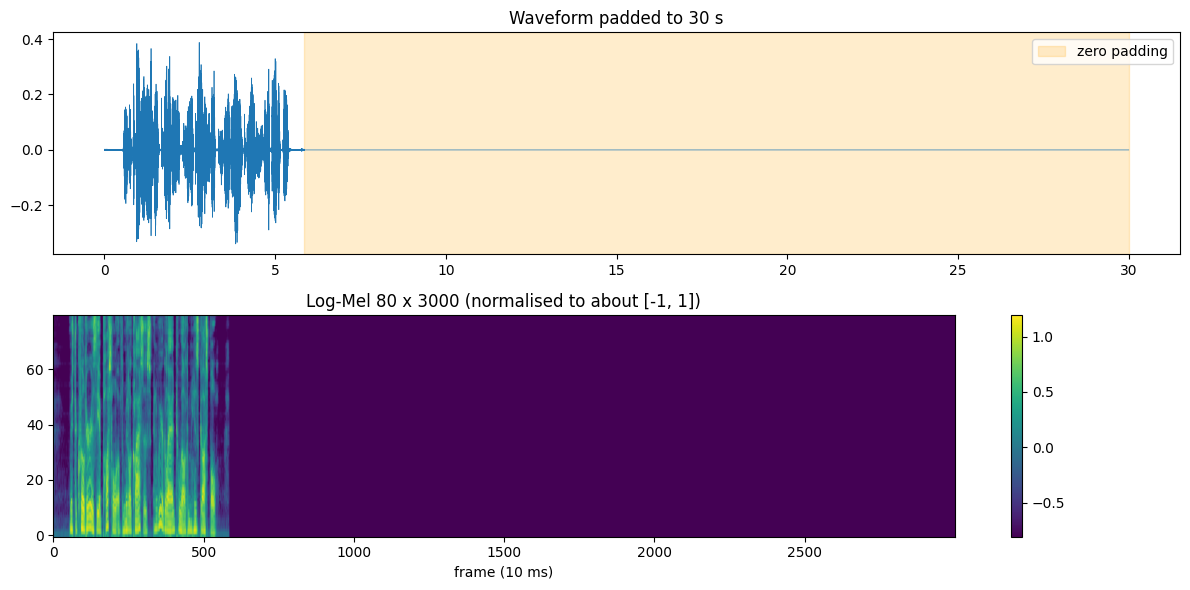

In [5]:
x = whisper.pad_or_trim(en_audio)  # 480000 samples
mel = whisper.log_mel_spectrogram(x, n_mels=model.dims.n_mels)
print("raw:", en_audio.shape, "-> padded:", x.shape, "-> mel:", tuple(mel.shape))

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].plot(np.arange(len(x)) / 16000, x, lw=.5)
ax[0].axvspan(len(en_audio) / 16000, 30, color="orange", alpha=.2, label="zero padding")
ax[0].set_title("Waveform padded to 30 s"); ax[0].legend()
im = ax[1].imshow(mel.numpy(), aspect="auto", origin="lower", cmap="viridis")
ax[1].set_title("Log-Mel 80 x 3000 (normalised to about [-1, 1])"); ax[1].set_xlabel("frame (10 ms)")
plt.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

Most of this matrix is just padding. On short clips that silent part is where Whisper sometimes makes up text (more on that in the guide, section 6).

## 3. Inside the model: shape trace
I put forward hooks on a few layers to print what comes out of each one.

In [8]:
shapes = {}
for mod in model.modules(): mod._forward_hooks.clear()  # drop hooks left over from a failed run
def hook(name):
    def fn(m, i, o): shapes[name] = tuple(o.shape)  # must return None, otherwise it replaces the output
    return fn
hs = [model.encoder.conv1.register_forward_hook(hook("conv1")),
      model.encoder.conv2.register_forward_hook(hook("conv2 (stride 2)")),
      model.encoder.blocks[-1].register_forward_hook(hook("encoder out"))]
with torch.no_grad():
    audio_feat = model.embed_audio(mel.unsqueeze(0).to(DEVICE))
    tok = whisper.tokenizer.get_tokenizer(model.is_multilingual, language="en", task="transcribe")
    prefix = torch.tensor([list(tok.sot_sequence_including_notimestamps)], device=DEVICE)
    logits = model.logits(prefix, audio_feat)
for h in hs: h.remove()
shapes["decoder logits"] = tuple(logits.shape)
for k, v in shapes.items(): print(f"{k:18s} {v}")
print("prefix tokens:", [tok.decode([t]) for t in prefix[0].tolist()])


conv1              (1, 512, 3000)
conv2 (stride 2)   (1, 512, 1500)
encoder out        (1, 1500, 512)
decoder logits     (1, 4, 51865)
prefix tokens: ['<|startoftranscript|>', '<|en|>', '<|transcribe|>', '<|notimestamps|>']


The shapes match the paper. The 3000 Mel frames go in, the second conv layer halves the time axis to 1500 positions (20 ms each), and that's what the decoder attends to. The decoder gets 4 starting tokens (start, language, task, no timestamps) and gives back a score for each of the 51,865 tokens in the vocabulary.

For `base` (d=512) the expected shapes are: conv1 `(1,512,3000)`, conv2 `(1,512,1500)`, encoder `(1,1500,512)`, logits `(1, 4, 51865)`.

## 4. Special tokens
### 4a. Language detection
This is just one decoder step on the start token, then reading the probabilities of the language tokens.

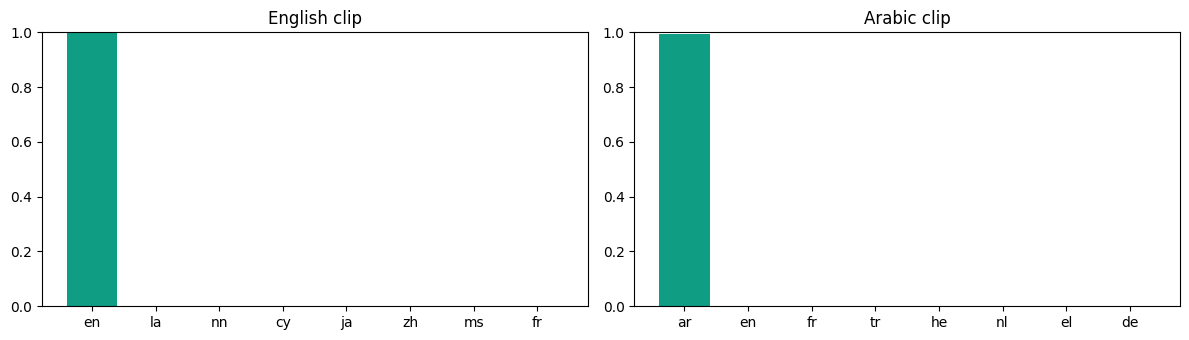

In [9]:
def lang_probs(audio, k=8):
    m = whisper.log_mel_spectrogram(whisper.pad_or_trim(audio), n_mels=model.dims.n_mels).to(DEVICE)
    _, probs = model.detect_language(m)
    return sorted(probs.items(), key=lambda kv: -kv[1])[:k]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, (name, audio) in zip(ax, [("English clip", en_audio), ("Arabic clip", ar_audio)]):
    top = lang_probs(audio)
    a.bar([l for l, _ in top], [p for _, p in top], color="#0F9D84"); a.set_title(name); a.set_ylim(0, 1)
plt.tight_layout(); plt.show()

### 4b. Same Arabic audio, two tasks: transcribe vs translate

In [10]:
for task in ["transcribe", "translate"]:
    r = model.transcribe(ar_audio, language="ar", task=task, fp16=FP16)
    print(f"{task:10s} -> {r['text']}")

transcribe ->  الحجف لاادت مش مجرد شد الحجف نحتك تنظيم بتركيز في التفاصيل في المجرد التوبي السقة والردسرية مهمي جدا وأخل بأسئل تلمرضة بتتكارر every second AI بيفة ملاادت بثاتك الأول من خلال جايدت أو مبورتين أو إنك ترفع لخدمتك وأنها جلسات والأصاة والدكترة والمعي وبعدها بيوردفورا بيفة حارة المريد وبسنفة طورك كشف متابعة ويجل مع بينها تلمريد كاملة في شيط ويعمل لكسكور الحالة ويعرف كل أهم في الأهم وفي الأخير تستيلم بات العاملة متراتتبة وبينت كاملة داش بوردوعة ويجهزلك المكتبط طوصل معهم وضبط معيدة والحجوزات ويكون المريد وأفنس أو محتاج من نكم طبع بين بهاك فوران ويقولك الحالة وصلت لأين عشان تقدر تكامل طوصل معا وتطبع every second AI مش مجرد ردود على رسايل لا زيكا استطنعي بيشتال مكان فريق كامل ويحولك الرسايل والدات المقلوبة يجهز جهزة من غير داخت وفوقت أن مرضه وبهتم بكل طفسيلة every second AI راح للفري وطنزين دلائات خلال حجزي زك ومرح وقرب بنفسك فريتل سرائيا
translate  ->  There are no rejects in traditional presented articles details of the term the story of a 45-year-old AA-show and, among other t

What I noticed here:
- The transcription is rough but you can read it. Most mistakes come from how Egyptians pronounce things. We say ج as "g", so الحجز turns into الحقز or الحجف, and ث becomes س (الثقة becomes السقة).
- The English words said ("every second AI") come out in English letters, but in my ground truth I wrote them in Arabic letters (افري سكند اي اي). So they count as errors even though the model heard them correctly.
- The translation with `base` is completely made up. It talks about a 45-year-old, aliens, and even drops a Chinese token in there. A small model just can't translate dialect to English, you need large or turbo for that.

Tip: always pass `language="ar"` on short Arabic clips. Auto detection sometimes confuses Arabic with Persian or Urdu.

## 5. Long-form decoding
### 5a. Timestamp timeline
I glued English, Arabic and English together to fake code-switching, then plotted the segments.
The catch is that `transcribe()` detects the language once, from the first 30 seconds, and keeps it for the whole file. So the top plot is a single pass, and the bottom one runs each clip with its own language.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 8.8 MB/s eta 0:00:00
single pass detected language: ar


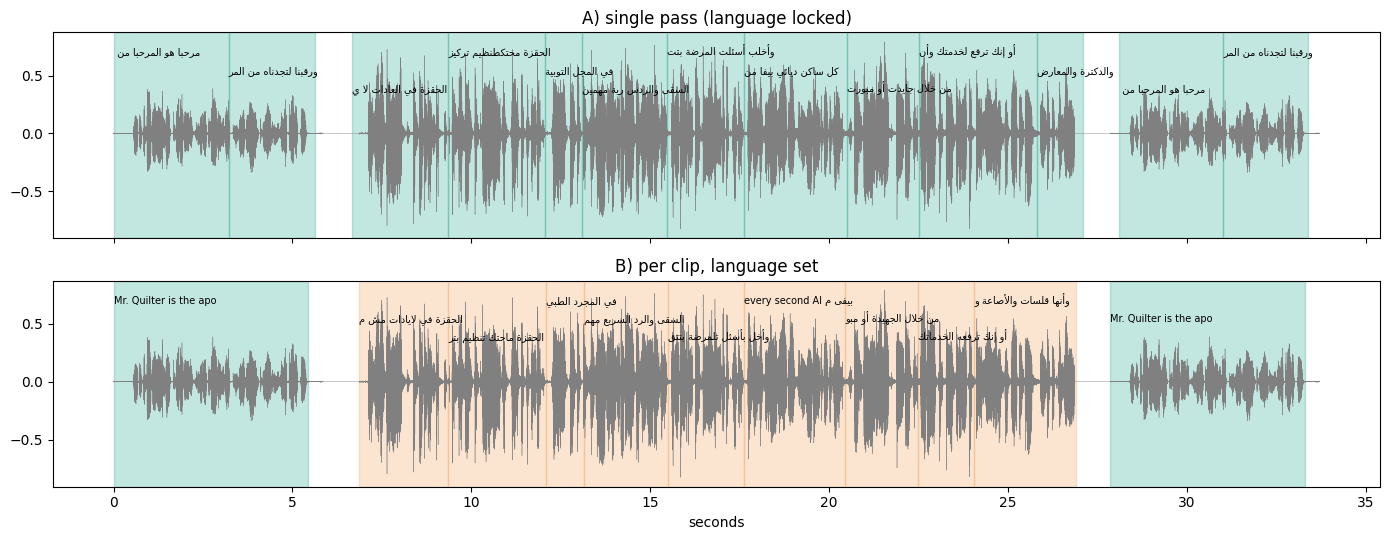

[ 0.00-> 5.44] en lp=-0.22 cr=1.09 nospeech=0.01 |  Mr. Quilter is the apostle of the middle classes, and we are glad to welcome his gospel.
[ 6.86-> 9.36] ar lp=-0.64 cr=1.82 nospeech=0.03 |  الحقزة في لايادات مش مجرد شد
[ 9.36->12.07] ar lp=-0.64 cr=1.82 nospeech=0.03 |  الحقزة ماحتك تنظيم بتركيز في الطفصيل
[12.07->13.14] ar lp=-0.64 cr=1.82 nospeech=0.03 |  في المجرد الطبي
[13.14->15.50] ar lp=-0.64 cr=1.82 nospeech=0.03 |  السقى والرد السريع مهم مين جدا
[15.50->17.62] ar lp=-0.64 cr=1.82 nospeech=0.03 |  وأخل بأسئل تلمرضة بتتقرر
[17.62->20.45] ar lp=-0.64 cr=1.82 nospeech=0.03 |  every second AI بيفى ملايادات بتاعتك الأول
[20.45->22.50] ar lp=-0.64 cr=1.82 nospeech=0.03 |  من خلال الجهيدة أو مبورتين
[22.50->24.05] ar lp=-0.64 cr=1.82 nospeech=0.03 |  أو إنك ترفعه الخدماتك
[24.05->26.89] ar lp=-0.64 cr=1.82 nospeech=0.03 |  وأنها قلسات والأصاعة والدكترة والمعنة
[27.86->33.30] en lp=-0.22 cr=1.09 nospeech=0.01 |  Mr. Quilter is the apostle of the middle classes, and we are glad to we

In [12]:
!pip install -q arabic-reshaper python-bidi
import arabic_reshaper
from bidi.algorithm import get_display
def rtl(t): return get_display(arabic_reshaper.reshape(t))  # matplotlib can't shape/right-to-left Arabic on its own

gap = np.zeros(16000, np.float32)
clips = [("en", en_audio), ("ar", ar_audio[:20 * 16000]), ("en", en_audio)]
mix = np.concatenate([clips[0][1], gap, clips[1][1], gap, clips[2][1]])

# A) one pass: language locked from the first window
single = model.transcribe(mix, fp16=FP16)["segments"]
print("single pass detected language:", model.transcribe(mix[:30 * 16000], fp16=FP16)["language"])

# B) per clip with the right language, shifting timestamps by the clip offset
per_clip, off = [], 0.0
for lang, a in clips:
    for s in model.transcribe(a, language=lang, fp16=FP16)["segments"]:
        per_clip.append({**s, "start": s["start"] + off, "end": s["end"] + off, "lang": lang})
    off += (len(a) + len(gap)) / 16000

t = np.arange(len(mix)) / 16000
fig, axes = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
for ax, segs, title in [(axes[0], single, "A) single pass (language locked)"), (axes[1], per_clip, "B) per clip, language set")]:
    ax.plot(t, mix, lw=.3, color="gray")
    for k, s in enumerate(segs):
        c = "#0F9D84" if s.get("lang", "en") == "en" else "#F2994A"
        ax.axvspan(s["start"], s["end"], alpha=.25, color=c)
        ax.text(s["start"], (.85 - .2 * (k % 3)) * mix.max(), rtl(s["text"].strip()[:22]), fontsize=7)  # staggered labels
    ax.set_title(title)
axes[1].set_xlabel("seconds"); plt.tight_layout(); plt.show()

for s in per_clip:
    print(f"[{s['start']:5.2f}->{s['end']:5.2f}] {s['lang']} lp={s['avg_logprob']:.2f} cr={s['compression_ratio']:.2f} "
          f"nospeech={s['no_speech_prob']:.2f} | {s['text']}")
r = {"text": " ".join(s["text"] for s in per_clip)}  # used by 5b


What I noticed here:
- The single pass picked Arabic, because most of the first 30 seconds is Arabic. If I swap the order, English would win and the Arabic part would break instead.
- All the Arabic segments have the exact same numbers (`lp=-0.64 cr=1.82 nospeech=0.03`). That's because Whisper calculates these per 30 second window, not per sentence. So you can use them to filter windows, not single lines.
- The English part has a log-prob of -0.22 and the Arabic -0.64, so the model is a lot less sure about Arabic. That number is a cheap way to flag transcripts that someone should double check.

### 5b. Compression ratio check against hallucination
When the model gets stuck repeating itself, the text compresses really well. If the gzip ratio goes above 2.4, Whisper tries again with a higher temperature.

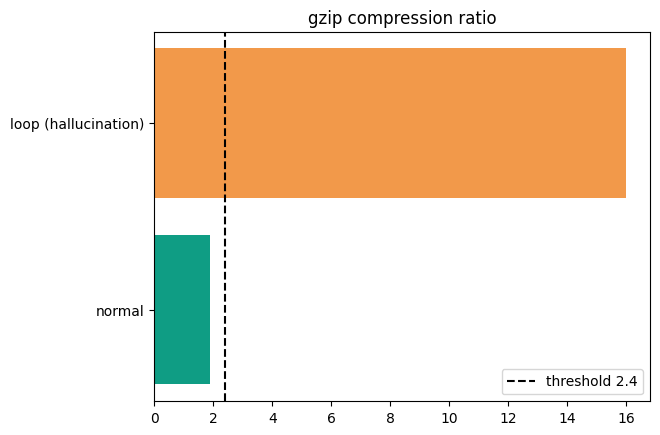

In [13]:
def cr(t): b = t.encode(); return len(b) / len(zlib.compress(b))
samples = {"normal": r["text"], "loop (hallucination)": "شكرا لكم " * 30}
plt.barh(list(samples), [cr(t) for t in samples.values()], color=["#0F9D84", "#F2994A"])
plt.axvline(2.4, ls="--", c="k", label="threshold 2.4"); plt.legend(); plt.title("gzip compression ratio"); plt.show()

## 6. Evaluate: WER & CER
For Arabic I normalise the text first (remove the tashkeel, make ا/أ/إ/آ the same, ة to ه, ى to ي). Otherwise small spelling differences count as errors.

In [14]:
import jiwer
def norm_ar(t):
    t = re.sub(r"[\u064B-\u0652\u0640]", "", t)  # tashkeel + tatweel
    t = re.sub("[إأآ]", "ا", t).replace("ة", "ه").replace("ى", "ي")
    return re.sub(r"[^\w\s]", "", t).strip()
def norm_en(t): return re.sub(r"[^\w\s]", "", t.lower()).strip()

en_hyp = model.transcribe(en_audio, language="en", fp16=FP16)["text"]
ar_hyp = model.transcribe(ar_audio, language="ar", fp16=FP16)["text"]
print("EN WER", round(jiwer.wer(norm_en(en_ref), norm_en(en_hyp)), 3))
print("AR WER", round(jiwer.wer(norm_ar(AR_REF), norm_ar(ar_hyp)), 3),
      "| CER", round(jiwer.cer(norm_ar(AR_REF), norm_ar(ar_hyp)), 3))

EN WER 0.059
AR WER 0.764 | CER 0.273


What I noticed here:
- English WER is 0.059, which is one wrong word out of 17. This sample is too easy, every model gets the same score on it (you'll see that in 6b).
- Arabic WER is 0.76 but CER is only 0.27. So around 3 out of 4 letters are correct, but most words still count as wrong, because one wrong letter (ج instead of ق, ة instead of ه, a missing ال) makes the whole word wrong. For Arabic I'd always report CER next to WER, WER alone makes the model look worse than it is.

Keep in mind the ground truth is Egyptian Arabic, with some English words written in Arabic letters (like افري سكند اي اي). So a big gap between English and Arabic is expected. Next I compare the model versions.

### 6b. Model versions
Same audio and same metrics, just different checkpoints. The `.en` models only do English, so they skip the Arabic clip. `turbo` is `large-v3-turbo`, which keeps the big encoder but only has 4 decoder layers instead of 32.

100%|██████████████████████████████████████| 72.1M/72.1M [00:00<00:00, 106MiB/s]


tiny     en WER=0.06 |  Mr. Quilter is the apostle of the middle classes and we are glad to w
tiny     ar WER=0.88 |  الحاجز في لادت مش مجرد شات الحاجز محتكز في التفاصيل في المجرد توبي أس
base     en WER=0.06 |  Mr. Quilter is the apostle of the middle classes, and we are glad to 
base     ar WER=0.76 |  الحجف لاادت مش مجرد شد الحجف نحتك تنظيم بتركيز في التفاصيل في المجرد 


100%|███████████████████████████████████████| 461M/461M [00:06<00:00, 73.0MiB/s]


small    en WER=0.06 |  Mr. Quilter is the apostle of the Middle Classes, and we are glad to 
small    ar WER=0.45 |  الحقز في العادات مش مجرد شد الحقز المحتاج تنظيم وتركيز في التفاصيل في


100%|█████████████████████████████████████| 1.51G/1.51G [00:31<00:00, 51.6MiB/s]


turbo    en WER=0.06 |  mr quilter is the apostle of the middle classes and we are glad to we
turbo    ar WER=0.24 |  الحاجز في الاعادات مش مجرد شات الحاجز محتاج تنظيم وتركيز في التفاصيل 


100%|██████████████████████████████████████| 72.1M/72.1M [00:00<00:00, 150MiB/s]


tiny.en  en WER=0.06 |  Mr. Quilter is the apostle of the middle classes and we are glad to w


100%|████████████████████████████████████████| 139M/139M [00:01<00:00, 141MiB/s]


base.en  en WER=0.06 |  Mr. Quilter is the apostle of the middle classes, and we are glad to 


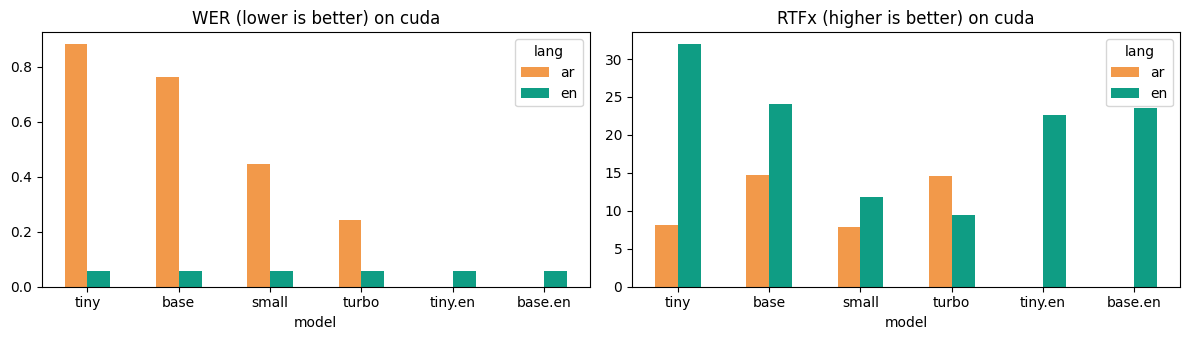

,model,lang,WER,CER,RTFx,hyp
0,tiny,en,0.059,0.045,31.920,Mr. Quilter is the apostle of the middle clas...
1,tiny,ar,0.882,0.487,8.076,الحاجز في لادت مش مجرد شات الحاجز محتكز في ال...
2,base,en,0.059,0.045,24.101,Mr. Quilter is the apostle of the middle clas...
3,base,ar,0.764,0.273,14.759,الحجف لاادت مش مجرد شد الحجف نحتك تنظيم بتركي...
4,small,en,0.059,0.045,11.819,Mr. Quilter is the apostle of the Middle Clas...
5,small,ar,0.447,0.131,7.893,الحقز في العادات مش مجرد شد الحقز المحتاج تنظ...
6,turbo,en,0.059,0.045,9.476,mr quilter is the apostle of the middle class...
7,turbo,ar,0.242,0.110,14.562,الحاجز في الاعادات مش مجرد شات الحاجز محتاج ت...
8,tiny.en,en,0.059,0.045,22.661,Mr. Quilter is the apostle of the middle clas...
9,base.en,en,0.059,0.045,23.499,Mr. Quilter is the apostle of the middle clas...


In [15]:
import gc, pandas as pd
MODELS = ["tiny", "base", "small", "turbo", "tiny.en", "base.en"]  # drop "turbo" if Colab RAM is tight
rows = []
for name in MODELS:
    m = whisper.load_model(name, device=DEVICE)
    for lang, audio, ref, norm in [("en", en_audio, en_ref, norm_en), ("ar", ar_audio, AR_REF, norm_ar)]:
        if name.endswith(".en") and lang == "ar": continue
        t0 = time.time(); hyp = m.transcribe(audio, language=lang, fp16=FP16)["text"]; dt = time.time() - t0
        rows.append(dict(model=name, lang=lang, WER=jiwer.wer(norm(ref), norm(hyp)), CER=jiwer.cer(norm(ref), norm(hyp)),
                         RTFx=len(audio) / 16000 / dt, hyp=hyp[:70]))
        print(f"{name:8s} {lang} WER={rows[-1]['WER']:.2f} | {hyp[:70]}")
    del m; gc.collect()
    if DEVICE == "cuda": torch.cuda.empty_cache()

df = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, metric in zip(ax, ["WER", "RTFx"]):
    df.pivot(index="model", columns="lang", values=metric).reindex(MODELS).plot.bar(ax=a, color=["#F2994A", "#0F9D84"], rot=0)
    a.set_title(f"{metric} ({'lower' if metric == 'WER' else 'higher'} is better) on {DEVICE}")
plt.tight_layout(); plt.show()
df.round(3)

Arabic results:

| | tiny | base | small | turbo |
|---|---|---|---|---|
| WER | 0.88 | 0.76 | 0.45 | 0.24 |
| CER | 0.49 | 0.27 | 0.13 | 0.11 |

- Model size matters a lot more for Arabic than for English. English stays at 0.059 for all of them, while Arabic WER goes from 0.88 down to 0.24.
- Turbo ran Arabic at the same speed as base (14.6x vs 14.8x real time) and is about 3 times more accurate. Most of the time is spent in the decoder, and turbo only has 4 decoder layers. For me this is the best choice.
- The `.en` models didn't help here because the English clip is already almost perfect. They'd make more of a difference on harder English audio with accents or noise.

## 7. CPU vs GPU, offline vs online
### 7a. CPU vs GPU with faster-whisper
Same Arabic clip on CPU (int8) and GPU (float16). The weights download once, and after that it all runs locally.

cpu  tiny            x5.6 real time | WER 0.84 |  الحاجز في العالات مشموك الرجات  الحاجز نحتككمزين بتركيز في 
cpu  base            x3.6 real time | WER 0.69 |  الحقزة في لايادات مش مجرد شات  الحقزة ماحتك تنظيم متركيز في
cpu  small           x1.2 real time | WER 0.47 |  الحقز في العادات مش مجرد شد  الحقز المحتاج تنظيم وتركيز في 
cuda tiny            x27.4 real time | WER 0.83 |  الحاجز في العالات مشموك الرجات  الحاجز محتككمزين بتركيز في 
cuda base            x12.2 real time | WER 0.76 |  الحكز في العدد مش مقرهت شد  الحكز مش تاكتونظيم متركيس في ال
cuda small           x19.4 real time | WER 0.43 |  الحقز في العادات مش مجرد شد  الحقز المحتاج تنظيم وتركيز في 
cuda large-v3-turbo  x19.4 real time | WER 0.21 |  الحاجز في الايادات مش مجرد شات  الحاجز محتاج تنظيم وتركيز ف


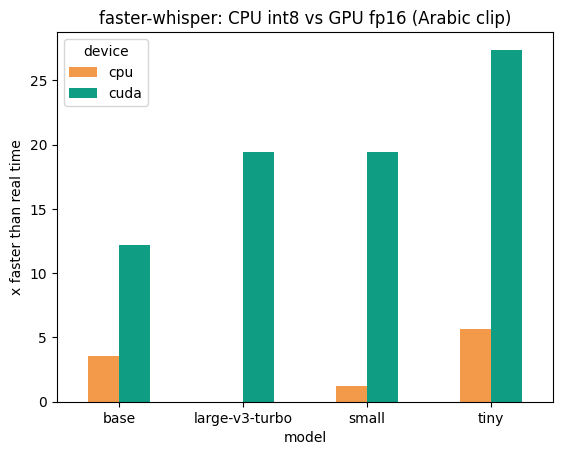

,device,model,RTFx,WER
0,cpu,tiny,5.618,0.839
1,cpu,base,3.559,0.689
2,cpu,small,1.222,0.466
3,cuda,tiny,27.381,0.826
4,cuda,base,12.163,0.764
5,cuda,small,19.393,0.435
6,cuda,large-v3-turbo,19.421,0.211


In [17]:
from faster_whisper import WhisperModel
import ctypes, glob, site, subprocess, sys

def cuda12_libs():
    # faster-whisper (CTranslate2 4.x) needs cuBLAS 12 + cuDNN 9; Colab's torch may ship other versions or hide them
    pat = lambda: sorted(glob.glob(f"{site.getsitepackages()[0]}/nvidia/*/lib/lib*.so.*"))
    need = lambda: not any("libcublas.so.12" in p for p in pat())
    if need():
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nvidia-cublas-cu12", "nvidia-cudnn-cu12==9.*"], check=True)
    ok = 0
    for lib in [p for p in pat() if "cublas" in p or "cudnn" in p]:  # preload so CTranslate2 finds them by name
        try: ctypes.CDLL(lib, mode=ctypes.RTLD_GLOBAL); ok += 1
        except OSError: pass
    return not need() and ok > 0

devices = ["cpu"]
if torch.cuda.is_available():
    if cuda12_libs(): devices.append("cuda")
    else: print("GPU skipped: could not load cuBLAS 12 / cuDNN 9")

SIZES = {"cpu": ["tiny", "base", "small"], "cuda": ["tiny", "base", "small", "large-v3-turbo"]}  # turbo on CPU is slow
bench = []
for dev in devices:
    for size in SIZES[dev]:
        try:
            fw = WhisperModel(size, device=dev, compute_type="float16" if dev == "cuda" else "int8")
            t0 = time.time(); segs, info = fw.transcribe(ar_audio, language="ar", vad_filter=True, beam_size=5)
            hyp = " ".join(s.text for s in segs); dt = time.time() - t0  # segs is lazy: decoding happens here
        except RuntimeError as e:
            print(f"{dev} {size} failed: {e}"); continue
        bench.append(dict(device=dev, model=size, RTFx=len(ar_audio) / 16000 / dt, WER=jiwer.wer(norm_ar(AR_REF), norm_ar(hyp))))
        print(f"{dev:4s} {size:15s} x{bench[-1]['RTFx']:.1f} real time | WER {bench[-1]['WER']:.2f} | {hyp[:60]}")
        del fw; gc.collect()

bdf = pd.DataFrame(bench)
bdf.pivot(index="model", columns="device", values="RTFx").plot.bar(rot=0, color=["#F2994A", "#0F9D84"][:bdf.device.nunique()])
plt.ylabel("x faster than real time"); plt.title("faster-whisper: CPU int8 vs GPU fp16 (Arabic clip)"); plt.show()
bdf.round(3)

What I noticed here:
- The bigger the model, the more the GPU helps. Tiny gets about 5x faster (5.6 to 27.4), small gets about 16x faster (1.2 to 19.4). On CPU, small is barely real time, so on CPU I'd stick with tiny or base.
- `large-v3-turbo` on the T4 did the 69.5 second clip in around 3.6 seconds, with the best WER (0.21). The tiny and base numbers on GPU are a bit off because of CUDA warm-up on the first runs, that's why small looks faster than base.
- int8 on CPU is almost as accurate as fp16 on GPU (0.47 vs 0.43 for small), so quantising doesn't cost much.
- Turbo here got 0.21 while the openai-whisper turbo in 6b got 0.24. I think the difference comes from beam search (`beam_size=5`) and the VAD filter, since openai-whisper used greedy decoding.

`vad_filter=True` cuts the silence before decoding, it's the easiest way to reduce hallucinations. On CPU use int8, and for phones or edge devices look at whisper.cpp.

### 7b. Fully offline
Here I block the Hugging Face Hub and load the model only from the cache that 7a already filled. This is basically how you'd run it on a server with no internet, you just copy the cache folder over.

In [19]:
os.environ["HF_HUB_OFFLINE"] = "1"
try:
    # local_files_only=True: load from the cache only, error instead of downloading
    fw = WhisperModel("base", device=DEVICE, compute_type="float16" if FP16 else "int8", local_files_only=True)
    # pass the decoded array, not the path: new PyAV versions break faster-whisper's file decoder
    segs, _ = fw.transcribe(ar_audio, language="ar", vad_filter=True)
    print("OFFLINE ->", " ".join(s.text for s in segs)[:150])
    del fw
finally:
    os.environ.pop("HF_HUB_OFFLINE")  # back online for 7c

OFFLINE ->  الحجف لاادت مش مجرد شت  الحجف ماحتك تنظيم متاركيز في التفاصيل  في المجرد الطبي  الساقة والردس سرية مهمين جدا  وأخل بأسئلة المرضة بتتكارر  every secon


It gave the same `base` transcript with the Hub blocked, so it really ran from the local cache. If you copy `~/.cache/huggingface` to a machine with no internet, it works the same way.

### 7c. Online APIs (no OpenAI key needed)
Here the audio gets uploaded to the provider, and you get large-v3 quality without needing a GPU. You can get free keys and save them as Colab secrets (the key icon on the left):
- Hugging Face: huggingface.co > Settings > Access Tokens, save it as `HF_TOKEN`
- Groq (really fast, has a free tier): console.groq.com > API Keys, save it as `GROQ_API_KEY`
- OpenAI (`OPENAI_API_KEY`) is optional. If a key is missing that part is just skipped.

In [20]:
import requests
def secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.getenv(name)

online = []
def report(provider, text, dt):
    w = jiwer.wer(norm_ar(AR_REF), norm_ar(text)); online.append(dict(provider=provider, WER=w, sec=dt))
    print(f"{provider:30s} {dt:5.1f}s WER {w:.2f} | {text[:80]}")

if tok_hf := secret("HF_TOKEN"):
    from huggingface_hub import InferenceClient
    t0 = time.time()
    try:
        out = InferenceClient(token=tok_hf).automatic_speech_recognition(AR_PATH, model="openai/whisper-large-v3")
        report("HF whisper-large-v3", out.text, time.time() - t0)
    except Exception as e: print("HF failed:", e)
else: print("Skipped Hugging Face: add HF_TOKEN secret")

if tok_groq := secret("GROQ_API_KEY"):
    for gm in ["whisper-large-v3", "whisper-large-v3-turbo"]:
        t0 = time.time()
        with open(AR_PATH, "rb") as f:
            r_ = requests.post("https://api.groq.com/openai/v1/audio/transcriptions",
                               headers={"Authorization": f"Bearer {tok_groq}"},
                               files={"file": f}, data={"model": gm, "language": "ar"}, timeout=120)
        report(f"Groq {gm}", r_.json().get("text", str(r_.json())), time.time() - t0)
else: print("Skipped Groq: add GROQ_API_KEY secret")

if tok_oa := secret("OPENAI_API_KEY"):
    from openai import OpenAI
    t0 = time.time()
    with open(AR_PATH, "rb") as f:
        out = OpenAI(api_key=tok_oa).audio.transcriptions.create(model="whisper-1", file=f, language="ar")
    report("OpenAI whisper-1", out.text, time.time() - t0)
else: print("Skipped OpenAI (optional)")

Skipped Hugging Face: add HF_TOKEN secret
Groq whisper-large-v3            1.8s WER 0.21 |  الحجز في الهايادات مش مجرد شات الحجز محتاج تنظيم وتركيز في التفاصيل في المجال ا
Groq whisper-large-v3-turbo      0.8s WER 0.24 |  الحاجز في الاعادات مش مجرد شات الحاجز محتاج تنظيم وتركيز في التفاصيل في المجال 
Skipped OpenAI (optional)


What I noticed here:
- Groq `whisper-large-v3` got a WER of 0.21 in 1.8 seconds, and `large-v3-turbo` got 0.24 in 0.8 seconds, without using any GPU on my side.
- These are the same scores I got locally (0.24 for turbo, 0.21 for large-v3-turbo with faster-whisper), because the API runs the same open models. So picking online or offline isn't about quality, it's about privacy, cost and what hardware you have.
- I skipped Hugging Face in this run because I didn't set `HF_TOKEN`.

Online gives you the best quality with no setup, but your audio leaves your machine and you pay per minute after the free tier. Offline keeps everything private and free, but you need the hardware.

## Key takeaways from this run
1. English is basically solved, Egyptian Arabic isn't. Every model got 0.06 on English, and the best Arabic WER was 0.21.
2. Turbo is the one to use. It gives the best Arabic accuracy at the speed of base.
3. For Arabic always look at CER too. A WER of 0.76 was hiding a CER of 0.27.
4. Most of the remaining 0.21 isn't the model mishearing. It's dialect spelling (ج vs ق) and English words written in English letters while my ground truth has them in Arabic. Normalising those words or fine-tuning on Egyptian Arabic would fix exactly this.
5. Set the language yourself, and split audio that mixes languages, because detection only happens once.
6. faster-whisper on a GPU runs 16 to 19x real time. On CPU with int8, tiny and base are fine.

## Recap
| Concept | Where |
|---|---|
| 30 s audio to 80 x 3000 Mel | section 2 |
| Encoder 1500 x d, decoder cross-attention | section 3 |
| Task tokens, language ID, translate | section 4 |
| Timestamps and hallucination checks | section 5 |
| Arabic normalisation, WER/CER, tiny to turbo, .en | section 6 |
| CPU int8 vs GPU fp16 | 7a |
| Offline vs online APIs (HF, Groq, OpenAI) | 7b and 7c |

Next step: fine-tune `whisper-small` on Egyptian Arabic with Hugging Face `Seq2SeqTrainer` and compare the WER before and after.